In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
import streamlit
import os


In [5]:
df = pd.read_csv("/kaggle/input/datasets/wazuluvbby4sure/tmdb-movies/top10K-TMDB-movies.csv")
print(df.head())

      id                        title                 genre original_language  \
0    278     The Shawshank Redemption           Drama,Crime                en   
1  19404  Dilwale Dulhania Le Jayenge  Comedy,Drama,Romance                hi   
2    238                The Godfather           Drama,Crime                en   
3    424             Schindler's List     Drama,History,War                en   
4    240       The Godfather: Part II           Drama,Crime                en   

                                            overview  popularity release_date  \
0  Framed in the 1940s for the double murder of h...      94.075   1994-09-23   
1  Raj is a rich, carefree, happy-go-lucky second...      25.408   1995-10-19   
2  Spanning the years 1945 to 1955, a chronicle o...      90.585   1972-03-14   
3  The true story of how businessman Oskar Schind...      44.761   1993-12-15   
4  In the continuing saga of the Corleone crime f...      57.749   1974-12-20   

   vote_average  vote_coun

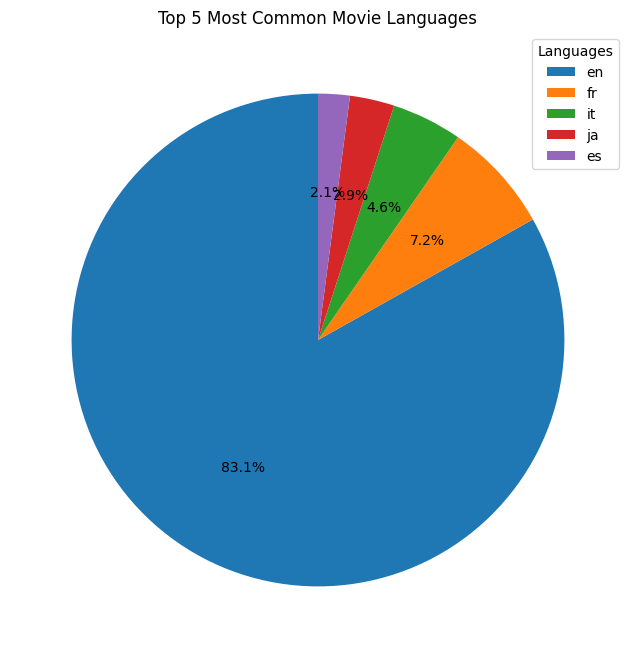

In [6]:
top5_lang = df["original_language"].value_counts().head(5)
plt.figure(figsize=(8, 8))
plt.pie(
    top5_lang,
    autopct="%1.1f%%",
    startangle=90
)
plt.legend(
    top5_lang.index,
    title="Languages",
    loc="best"
)
plt.title("Top 5 Most Common Movie Languages")
plt.show()

từ biểu đồ, ta thấy tiếng anh vẫn đang là ngôn ngữ phổ thông áp đảo với tỷ lệ 83.1%. Ngoài tiếng Anh, top 5 ghi nhận sự góp mặt của 3 ngôn ngữ Châu Âu (Pháp, Ý, Tây Ban Nha) và 1 ngôn ngữ Châu Á (Nhật Bản). Điều này phản ánh rằng ngoài Hollywood/phim tiếng Anh, thì điện ảnh Pháp, Ý, Tây Ban Nha và Anime/điện ảnh Nhật Bản là những nguồn sản xuất phim phổ biến

=>

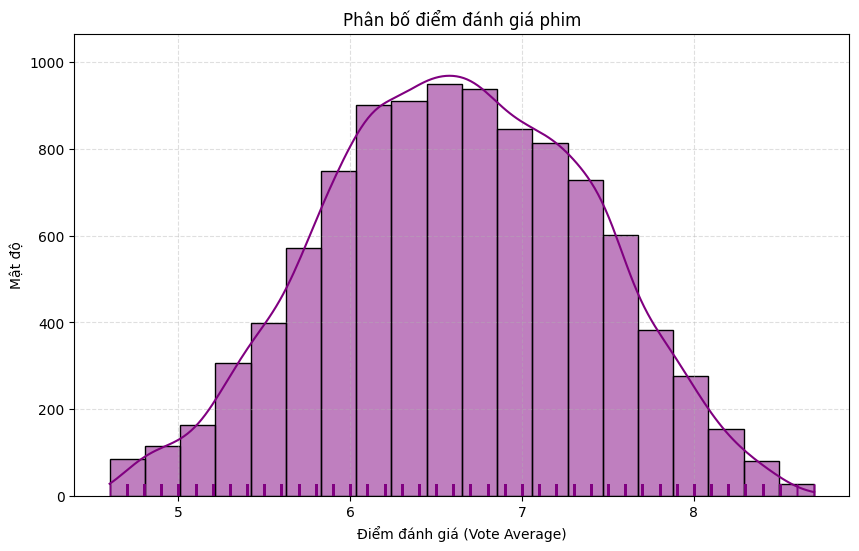

In [16]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["vote_average"],
    bins=20,
    kde=True,
    color="purple"
)

sns.rugplot(
    df["vote_average"],
    color="purple"
)

plt.title("Phân bố điểm đánh giá phim")
plt.xlabel("Điểm đánh giá (Vote Average)")
plt.ylabel("Mật độ")

plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

Biểu đồ có hình dáng dạng "hình chuông" đối xứng khá lý tưởng. Điều này cho thấy điểm số đánh giá phim tuân theo quy luật tự nhiên: đại đa số các bộ phim nằm ở mức trung bình, số lượng phim cực kỳ tệ hoặc cực kỳ xuất sắc chiếm tỷ lệ rất nhỏ.

Phần lớn các bộ phim tập trung dày đặc trong khoảng từ 6.0 đến 7.0 điểm. Đỉnh cao nhất nằm ở khoảng 6.5 - 6.7 điểm với gần 1000 bộ phim đạt mức này. Đây là mức điểm "an toàn" hoặc "xem ổn" của phần lớn phim điện ảnh trên các hệ thống đánh giá.


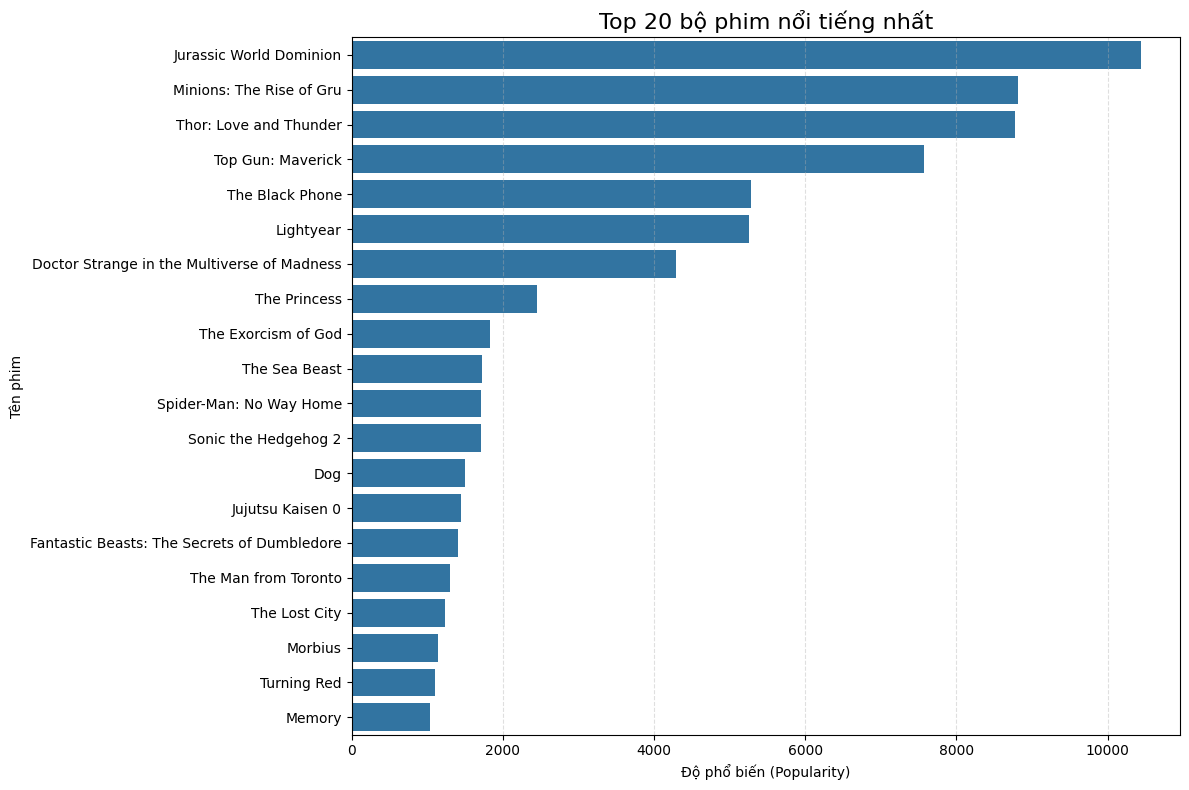

In [18]:
top20 = df.nlargest(20, "popularity")
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top20,
    x="popularity",
    y="title"
)

plt.title("Top 20 bộ phim nổi tiếng nhất", fontsize=16)
plt.xlabel("Độ phổ biến (Popularity)")
plt.ylabel("Tên phim")

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

/tmp/ipykernel_58/2919565105.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


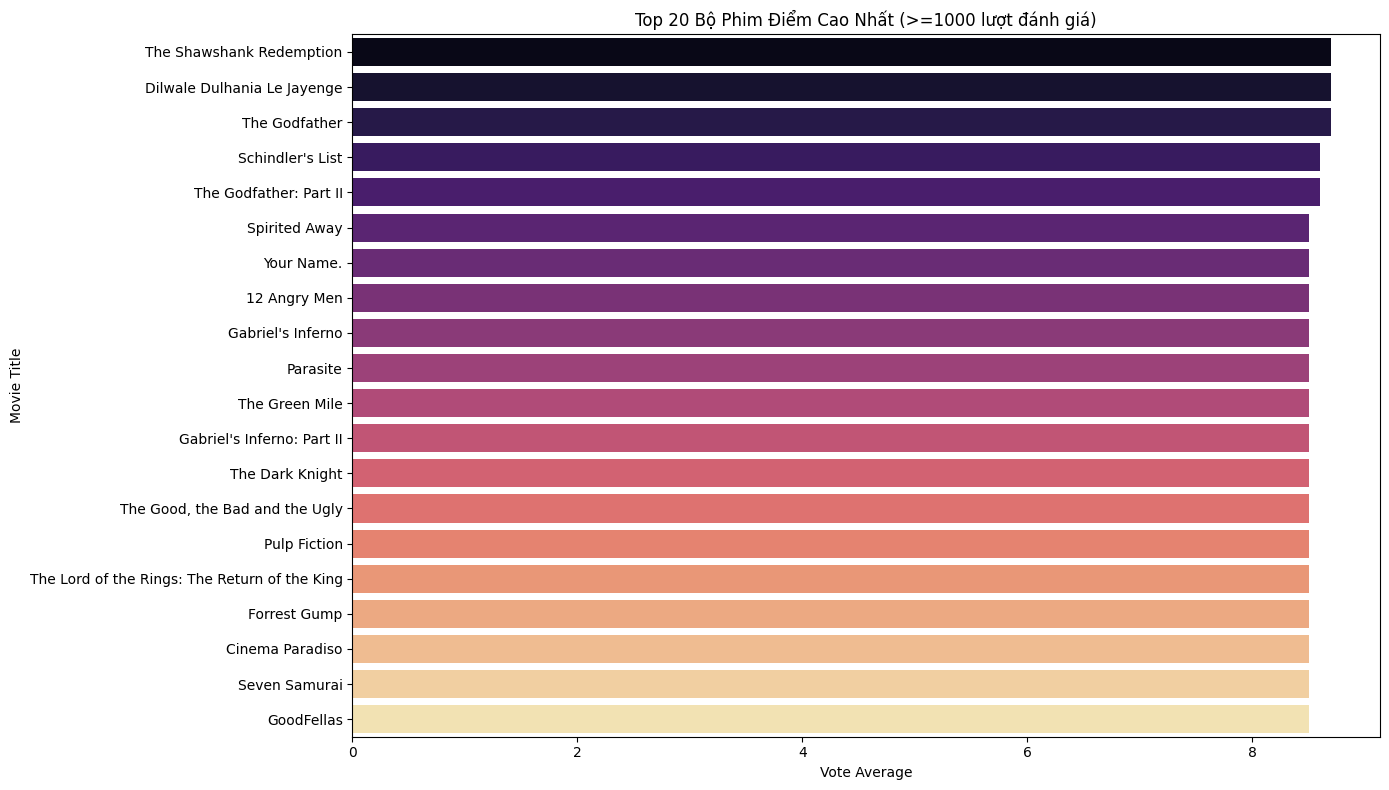

In [19]:
filtered = df[df["vote_count"] >= 1000]

top20 = filtered.nlargest(20, "vote_average")

plt.figure(figsize=(14, 8))

sns.barplot(
    data=top20,
    x="vote_average",
    y="title",
    palette="magma"
)

plt.title("Top 20 Bộ Phim Điểm Cao Nhất (>=1000 lượt đánh giá)")
plt.xlabel("Vote Average")
plt.ylabel("Movie Title")

plt.tight_layout()
plt.show()

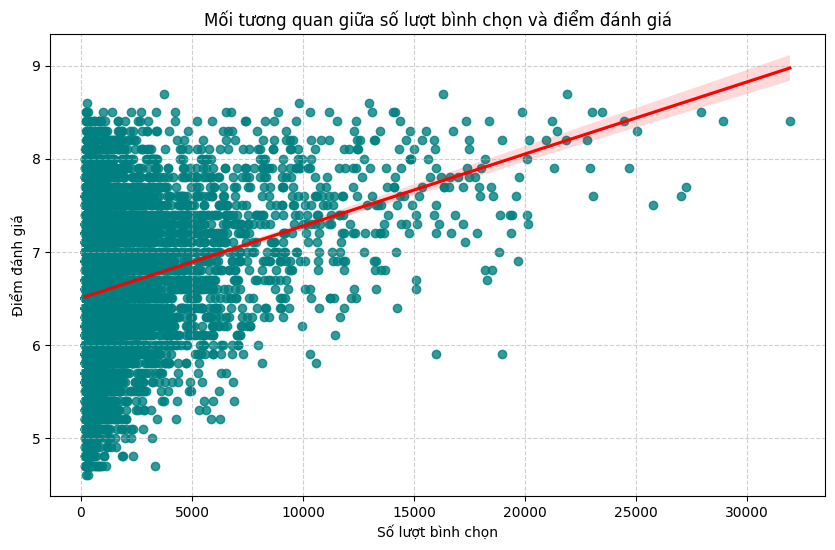

In [13]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="vote_count",
    y="vote_average",
    color="teal",
    line_kws={"color": "red"}
)

plt.title("Mối tương quan giữa số lượt bình chọn và điểm đánh giá")
plt.xlabel("Số lượt bình chọn")
plt.ylabel("Điểm đánh giá")

plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

Càng nhiều người bầu chọn, điểm càng cao: Đường hồi quy màu đỏ dốc lên rất rõ ràng. Điều này cho thấy một xu hướng: Những bộ phim có số lượng lượt bình chọn lớn (thu hút nhiều người xem và đánh giá) thường có xu hướng sở hữu điểm số trung bình cao hơn.

Ở nhóm phim có ít lượt bình chọn (dưới 5k lượt), dải điểm số trải rất rộng và phân tán mạnh (từ tệ dưới 5.0 cho đến xuất sắc trên 8.5). Tuy nhiên, khi số lượt bình chọn vượt qua mốc 15k, hầu như không còn bộ phim nào bị điểm dưới 6.0 nữa. Tất cả đều hội tụ ở phân khúc từ khá đến xuất sắc (7.0 - 9.0)

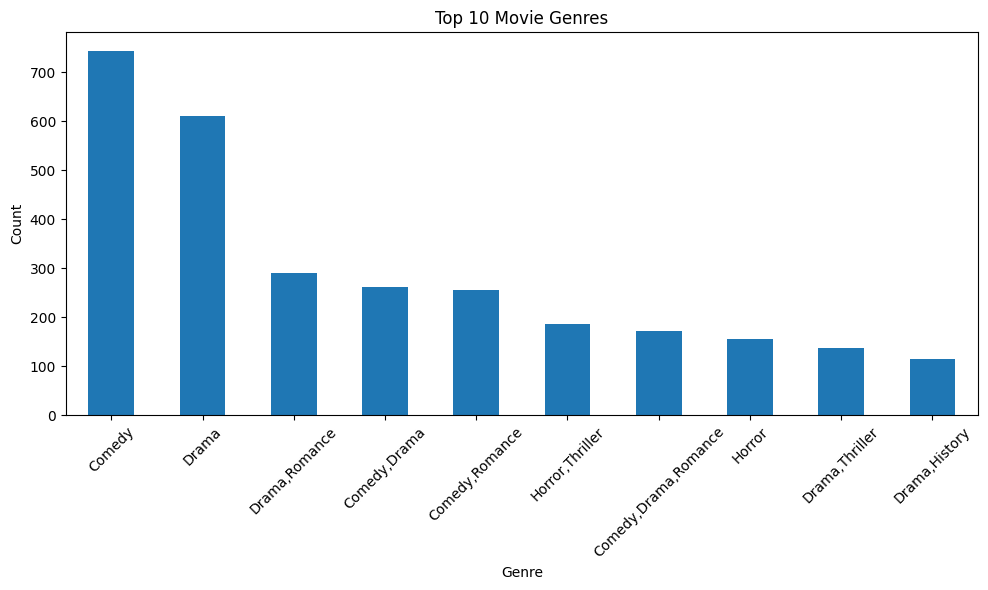

In [9]:
genre_count = df["genre"].value_counts().head(10)

plt.figure(figsize=(10, 6))
genre_count.plot(kind="bar")

plt.title("Top 10 Movie Genres")
plt.xlabel("Genre")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Số lượng phim thuộc hai thể loại này lớn gấp từ 2 đến 6 lần so với các vị trí tiếp theo trong danh sách. Điều này phản ánh xu hướng sản xuất phim đại chúng: Hài kịch và Chính kịch luôn là "món ăn tinh thần" dễ tiếp cận, chi phí sản xuất linh hoạt và có lượng khán giả đông đảo nhất.

=> Các nhà làm phim rất chuộng việc trộn lẫn các yếu tố cảm xúc (ví dụ: vừa hài hước vừa lãng mạn, vừa tâm lý vừa giật gân) để tăng tính hấp dẫn và mở rộng tệp khán giả, thay vì chỉ làm một thể loại thuần túy.

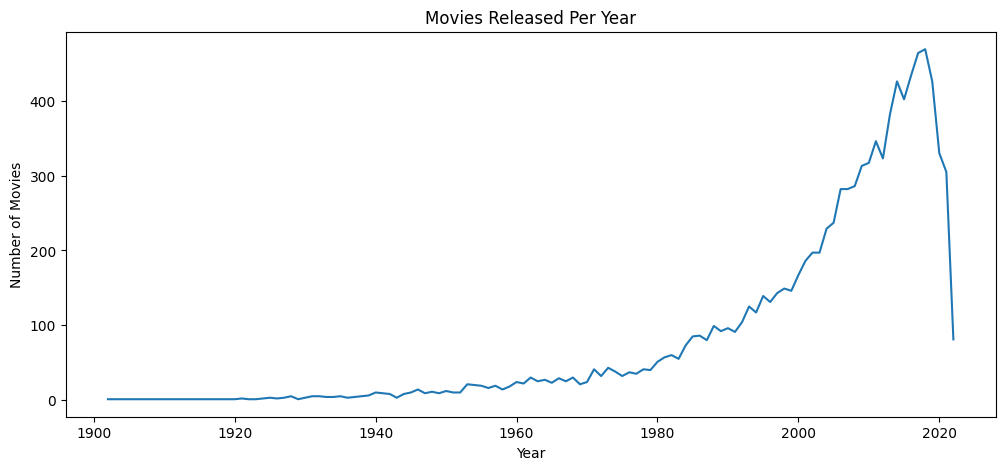

In [10]:
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year

movies_year = df["year"].value_counts().sort_index()

plt.figure(figsize=(12,5))
plt.plot(movies_year.index, movies_year.values)

plt.title("Movies Released Per Year")
plt.xlabel("Year")
plt.ylabel("Number of Movies")

plt.show()

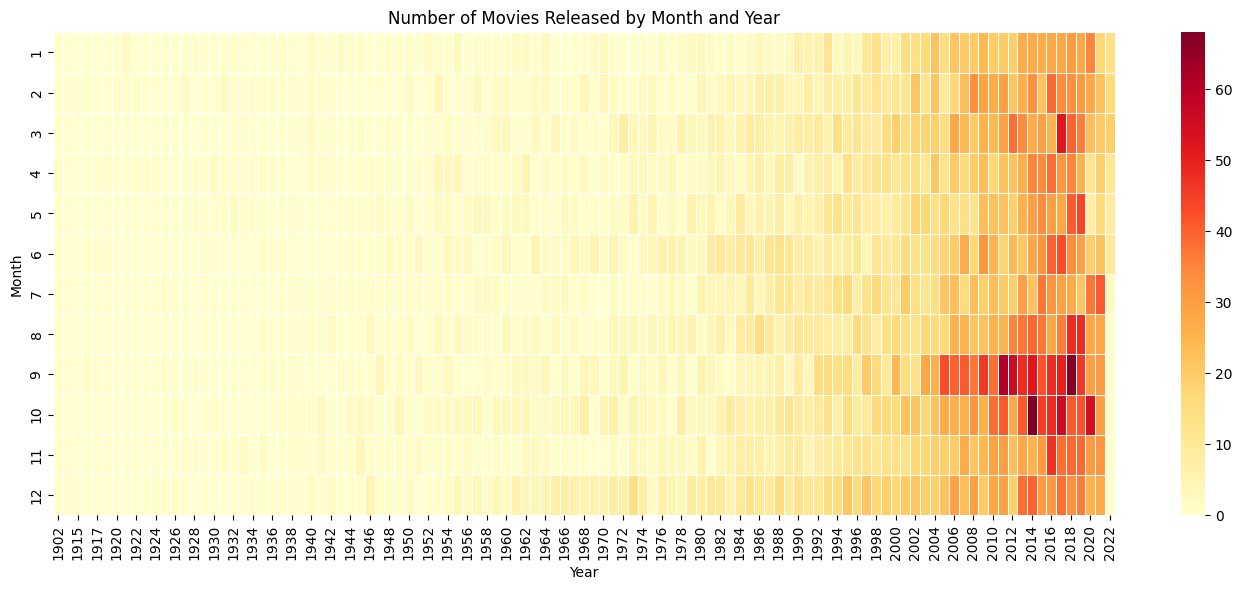

In [11]:
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")


df["year"] = df["release_date"].dt.year
df["month"] = df["release_date"].dt.month
heatmap_data = pd.crosstab(df["month"], df["year"])

plt.figure(figsize=(14, 6))
sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    linewidths=0.5
)
plt.title("Number of Movies Released by Month and Year")
plt.xlabel("Year")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

Giai đoạn trước năm 1990: Số lượng phim phát hành mỗi tháng cực kỳ ít (gần như bằng 0 hoặc chỉ dưới 10 phim). Điều này phản ánh thời kỳ sơ khai của điện ảnh, công nghệ làm phim còn hạn chế và số lượng phim sản xuất mỗi năm trên thế giới rất thấp

Giai đoạn 1990 - 2000: Ngành công nghiệp bắt đầu tăng tốc, số lượng phim tăng dần đều.

Giai đoạn từ năm 2000 đến nay: Sự bùng nổ toàn diện của điện ảnh toàn cầu. Số lượng phim được phát hành mỗi tháng tăng vọt, đỉnh điểm là giai đoạn 2010 - 2020 với những ô màu đỏ thẫm (trên 50-60 phim/tháng). Điều này gắn liền với sự phát triển của kỹ thuật số, dòng vốn đầu tư lớn và sự xuất hiện của các nền tảng trực tuyến.
=> Điện ảnh đang ngày càng phát triển với số lượng phim khổng lồ

In [60]:
df["genre"] = df["genre"].fillna("")
df["overview"] = df["overview"].fillna("")
df["text"] = df["genre"] + " " + df["overview"]

In [62]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 10000
MAX_LEN = 200

tokenizer = Tokenizer(num_words=MAX_WORDS)

tokenizer.fit_on_texts(df["text"])

X = tokenizer.texts_to_sequences(df["text"])

X = pad_sequences(
    X,
    maxlen=MAX_LEN
)

In [63]:
y = df["vote_average"].values

In [84]:
import tensorflow as tf
from tensorflow import keras

model = keras.Sequential([
    
    keras.layers.Embedding(
        input_dim=10000,
        output_dim=128,
        input_length=200
    ),

    keras.layers.GlobalAveragePooling1D(),

    keras.layers.Dense(
        128,
        activation="relu"
    ),

    keras.layers.Dropout(0.3),

    keras.layers.Dense(
        64,
        activation="relu"
    ),

    keras.layers.Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_4      │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [85]:
model.fit(
    X,
    y,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

# Save trained model and tokenizer
model.save('movie_model.keras')


Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.0000e+00 - loss: -89.5079 - val_accuracy: 0.0000e+00 - val_loss: -72.4103
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.0000e+00 - loss: -93.9056 - val_accuracy: 0.0000e+00 - val_loss: -72.4103
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.0000e+00 - loss: -93.9052 - val_accuracy: 0.0000e+00 - val_loss: -72.4103
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.0000e+00 - loss: -93.9156 - val_accuracy: 0.0000e+00 - val_loss: -72.4103
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.0000e+00 - loss: -93.9156 - val_accuracy: 0.0000e+00 - val_loss: -72.4103
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.0000e+00 - loss: -93.9156 - val_accuracy: 0.0000e+00 - val_loss: -72.4103
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.0000e+00 - loss: -93.9156 - val_accuracy: 0.0000e+00 - val_loss: -72.4103
Epoch 8/10
250/250 ━